In [ ]:
#Dimension Reduction Technique
#Variable Reduction Activity
#Unsupervised Learning Technique

In [ ]:
# PCA IMAGE COMPRESSION
# STEP 1: IMPORT LIBRARIES
# =============================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from skimage import data
print("Libraries imported successfully!")

Libraries imported successfully!


array([[200, 200, 200, ..., 189, 190, 190],
       [200, 199, 199, ..., 190, 190, 190],
       [199, 199, 199, ..., 190, 190, 190],
       ...,
       [ 25,  25,  27, ..., 139, 122, 147],
       [ 25,  25,  26, ..., 158, 141, 168],
       [ 25,  25,  27, ..., 151, 152, 149]], shape=(512, 512), dtype=uint8)
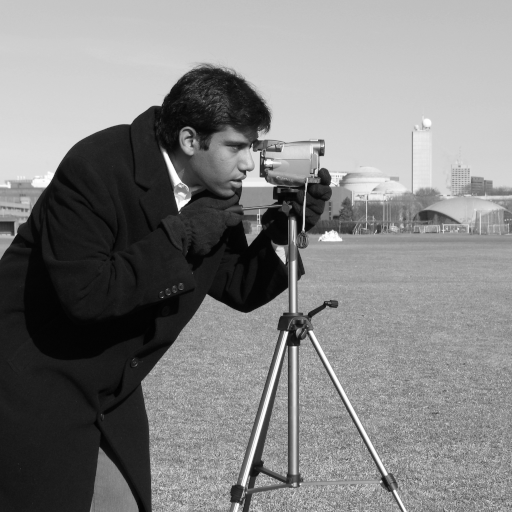

In [ ]:
# STEP 2: LOAD SAMPLE IMAGE
# ============================================================

# Load the famous Cameraman grayscale image
image = data.camera()
image

In [ ]:
# Convert image into floating point values
image = image.astype(float)
image


array([[200., 200., 200., ..., 189., 190., 190.],
       [200., 199., 199., ..., 190., 190., 190.],
       [199., 199., 199., ..., 190., 190., 190.],
       ...,
       [ 25.,  25.,  27., ..., 139., 122., 147.],
       [ 25.,  25.,  26., ..., 158., 141., 168.],
       [ 25.,  25.,  27., ..., 151., 152., 149.]], shape=(512, 512))

In [ ]:
print("Original Image Shape:", image.shape)

Original Image Shape: (512, 512)


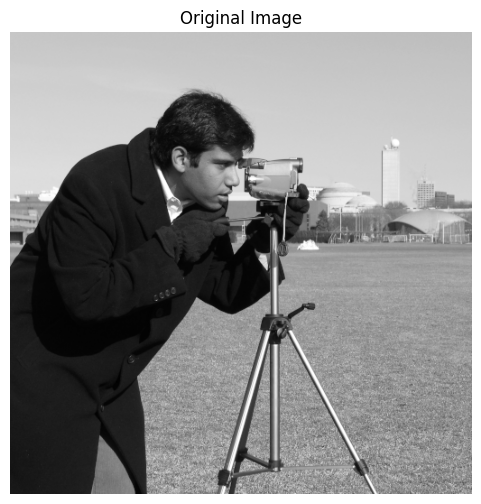

In [ ]:
# Display original image
plt.figure(figsize=(6,6))
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

In [ ]:
# STEP 3: UNDERSTAND IMAGE AS A MATRIX
# =============================================
# An image is represented using pixel values
# Each pixel contains an intensity value
print("Number of Rows:", image.shape[0])
print("Number of Columns:", image.shape[1])

Number of Rows: 512
Number of Columns: 512


In [ ]:
print("\nFirst 5 x 5 pixel values:")
print(image[:5, :5])


First 5 x 5 pixel values:
[[200. 200. 200. 200. 199.]
 [200. 199. 199. 200. 199.]
 [199. 199. 199. 200. 200.]
 [200. 200. 199. 199. 199.]
 [200. 200. 200. 200. 199.]]


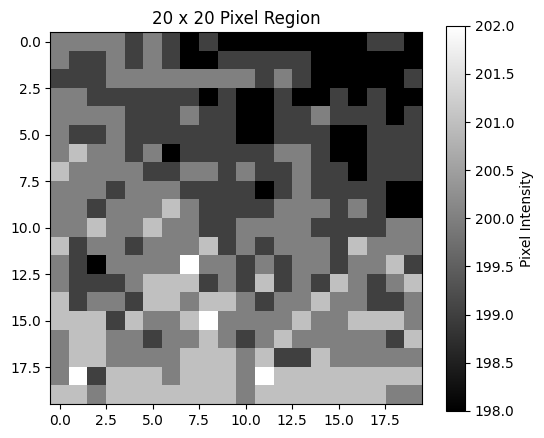

In [ ]:
# Display image as a numerical matrix
plt.figure(figsize=(6,5))
plt.imshow(image[:20, :20], cmap='gray')
plt.title("20 x 20 Pixel Region")
plt.colorbar(label="Pixel Intensity")
plt.show()

In [ ]:
# STEP 4: UNDERSTAND PCA
# PCA identifies the most important patterns
# It reduces the number of dimensions
# Here each image row is treated as one observation
pca_full = PCA()
pca_full.fit(image)
print("PCA completed!")
print("Total Components:", pca_full.n_components_)

PCA completed!
Total Components: 512


<Figure size 1000x500 with 0 Axes>

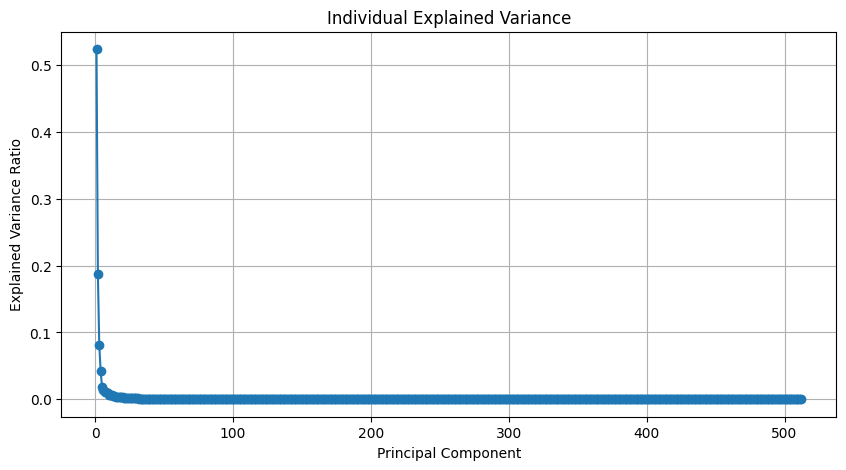

In [ ]:
# STEP 5: EXPLAINED VARIANCE DIAGRAM
# Explained variance shows information captured
# by each principal component
plt.figure(figsize=(10,5))
variance = pca_full.explained_variance_ratio_
plt.figure(figsize=(10,5))
plt.plot(range(1, len(variance)+1), variance, marker='o')

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")

plt.title("Individual Explained Variance")

plt.grid()
plt.show()

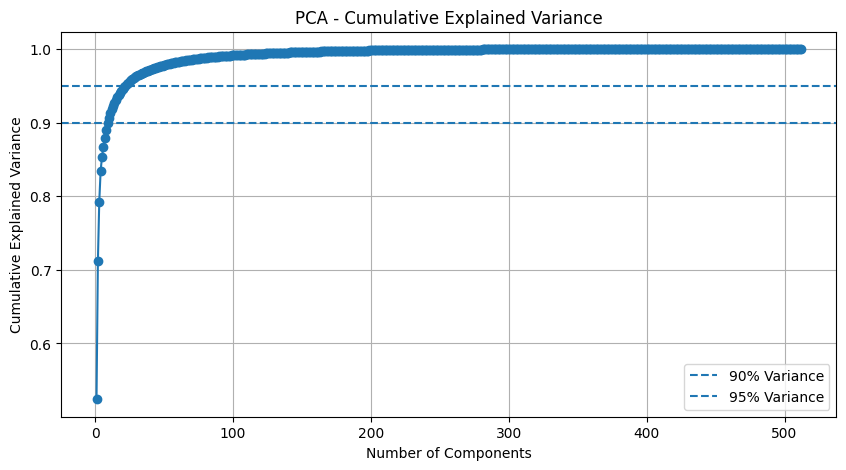

In [ ]:
# STEP 6: CUMULATIVE EXPLAINED VARIANCE
# ============================================================
# Cumulative variance shows total information retained
cumulative_variance = np.cumsum(variance)
plt.figure(figsize=(10,5))
plt.plot(
    range(1, len(cumulative_variance)+1),
    cumulative_variance,
    marker='o'
)

plt.axhline(y=0.90, linestyle='--', label="90% Variance")
plt.axhline(y=0.95, linestyle='--', label="95% Variance")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("PCA - Cumulative Explained Variance")

plt.legend()
plt.grid()
plt.show()

In [ ]:
# Find components needed for 90% variance
components_90 = np.argmax(cumulative_variance >= 0.90) + 1
print("Components required for 90% variance:", components_90)

Components required for 90% variance: 10


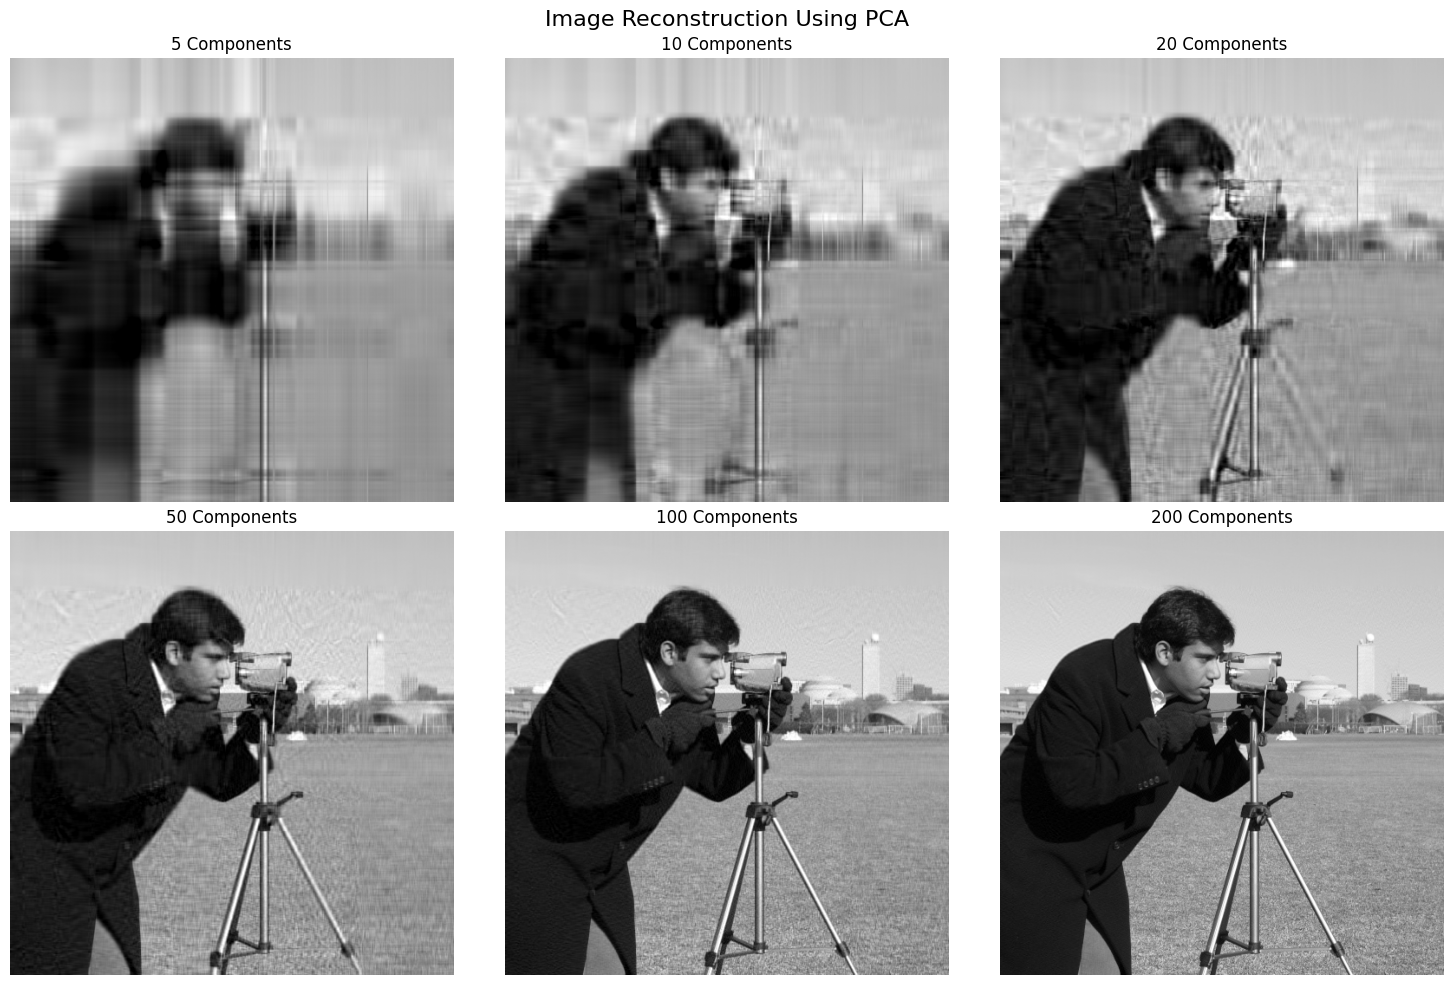

In [ ]:
# STEP 7: IMAGE COMPRESSION USING PCA
# ============================================================
# Try different numbers of principal components
components = [5, 10, 20, 50, 100, 200]
plt.figure(figsize=(15,10))

for i, k in enumerate(components):

    # Create PCA model
    pca = PCA(n_components=k)

    # Compress the image
    reduced_image = pca.fit_transform(image)

    # Reconstruct the image
    reconstructed_image = pca.inverse_transform(reduced_image)

    # Display reconstructed image
    plt.subplot(2,3,i+1)

    plt.imshow(
        reconstructed_image,
        cmap='gray',
        vmin=0,
        vmax=255
    )

    plt.title(str(k) + " Components")

    plt.axis('off')

plt.suptitle("Image Reconstruction Using PCA", fontsize=16)

plt.tight_layout()
plt.show()



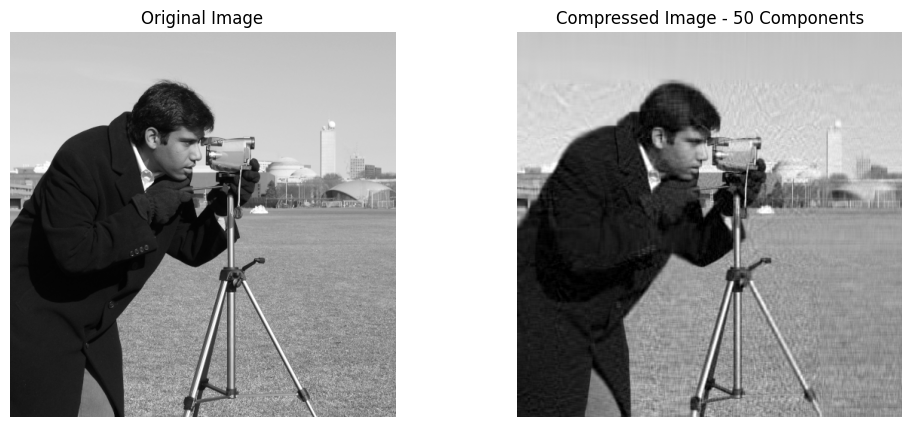

In [ ]:
# STEP 8: COMPARE ORIGINAL AND COMPRESSED IMAGE
# ================================================
# Display original image
# Select 50 components
k = 50

pca = PCA(n_components=k)

reduced_image = pca.fit_transform(image)

reconstructed_image = pca.inverse_transform(reduced_image)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.imshow(image, cmap='gray')

plt.title("Original Image")

plt.axis('off')


plt.subplot(1,2,2)

plt.imshow(
    reconstructed_image,
    cmap='gray',
    vmin=0,
    vmax=255
)

plt.title("Compressed Image - 50 Components")

plt.axis('off')

plt.show()



In [ ]:
# STEP 9: DISPLAY ORIGINAL VS RECONSTRUCTED PIXEL VALUES
# ============================================================
print("Original Pixel Values:")
print(image[:5, :5])
print("\nReconstructed Pixel Values:")
print(np.round(reconstructed_image[:5, :5], 2))

Original Pixel Values:
[[200. 200. 200. 200. 199.]
 [200. 199. 199. 200. 199.]
 [199. 199. 199. 200. 200.]
 [200. 200. 199. 199. 199.]
 [200. 200. 200. 200. 199.]]

Reconstructed Pixel Values:
[[198.4  198.49 199.05 199.85 200.21]
 [198.39 198.46 199.02 199.75 200.09]
 [198.87 199.02 199.59 200.31 200.64]
 [198.18 198.3  198.84 199.57 199.95]
 [198.75 198.83 199.37 200.03 200.31]]


In [ ]:
# STEP 10: CALCULATE RECONSTRUCTION ERROR
# ============================================================
# MSE measures the average squared difference
# between original and reconstructed pixels
mse = np.mean((image - reconstructed_image)**2)

# RMSE measures the square root of MSE

print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))

rmse = np.sqrt(mse)

Mean Squared Error: 88.07
Root Mean Squared Error: 9.38


In [ ]:
# STEP 11: CALCULATE COMPRESSION RATIO
# ============================================================
# Original image stores all pixel values
original_size = image.shape[0] * image.shape[1]
# PCA stores:
# 1. Reduced image representation
# 2. Principal component directions
# 3. Mean values

compressed_size = (
    image.shape[0] * k +
    k * image.shape[1] +
    image.shape[1]
)

compression_ratio = original_size / compressed_size
print("Original Values:", original_size)
print("Compressed Values:", compressed_size)
print("Compression Ratio:", round(compression_ratio, 2), ": 1")

Original Values: 262144
Compressed Values: 51712
Compression Ratio: 5.07 : 1


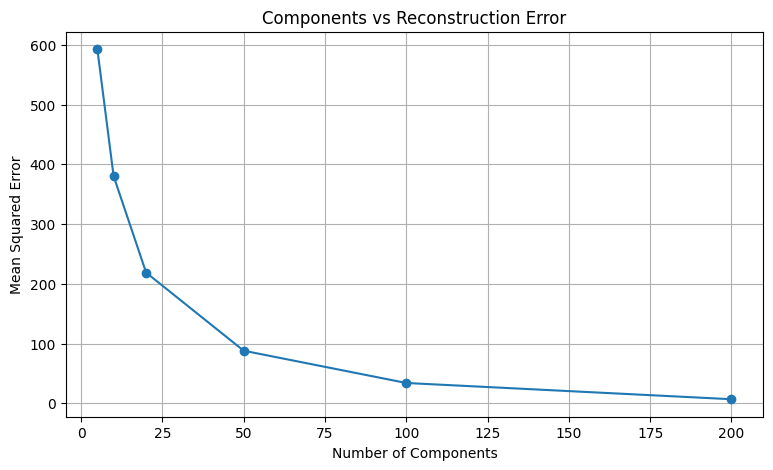

In [ ]:
# STEP 12: COMPONENTS VS RECONSTRUCTION ERROR
# ============================================================
component_list = [5, 10, 20, 50, 100, 200]
errors = []
for k in component_list:

    pca = PCA(n_components=k)

    reduced = pca.fit_transform(image)

    reconstructed = pca.inverse_transform(reduced)

    error = np.mean((image - reconstructed)**2)

    errors.append(error)

    # Plot reconstruction error

plt.figure(figsize=(9,5))
plt.plot(component_list, errors, marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Mean Squared Error")
plt.title("Components vs Reconstruction Error")
plt.grid()
plt.show()

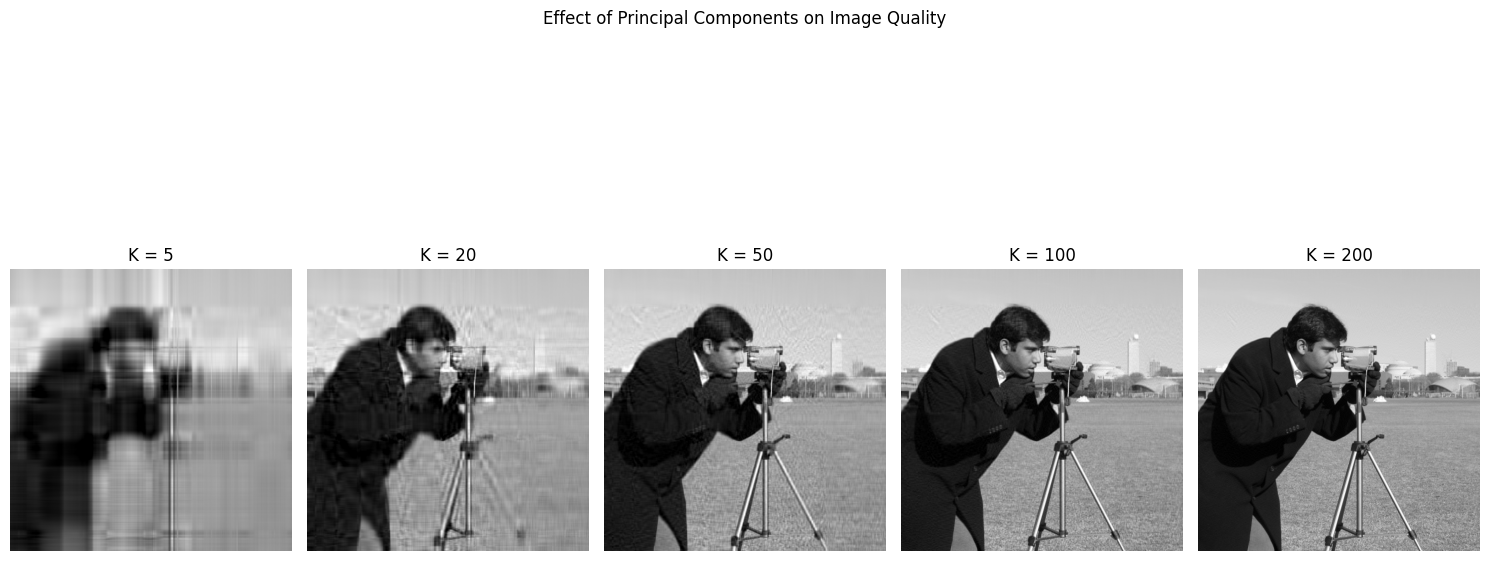

In [ ]:
# STEP 13: COMPONENTS VS IMAGE QUALITY
# ============================================================
# Display image reconstruction for selected components

component_list = [5, 20, 50, 100, 200]
plt.figure(figsize=(15,8))
for i, k in enumerate(component_list):
    pca = PCA(n_components=k)
    reduced = pca.fit_transform(image)
    reconstructed = pca.inverse_transform(reduced)
    plt.subplot(1,5,i+1)
    plt.imshow(reconstructed, cmap='gray', vmin=0, vmax=255)
    plt.title("K = " + str(k))
    plt.axis('off')
plt.suptitle("Effect of Principal Components on Image Quality")
plt.tight_layout()
plt.show()

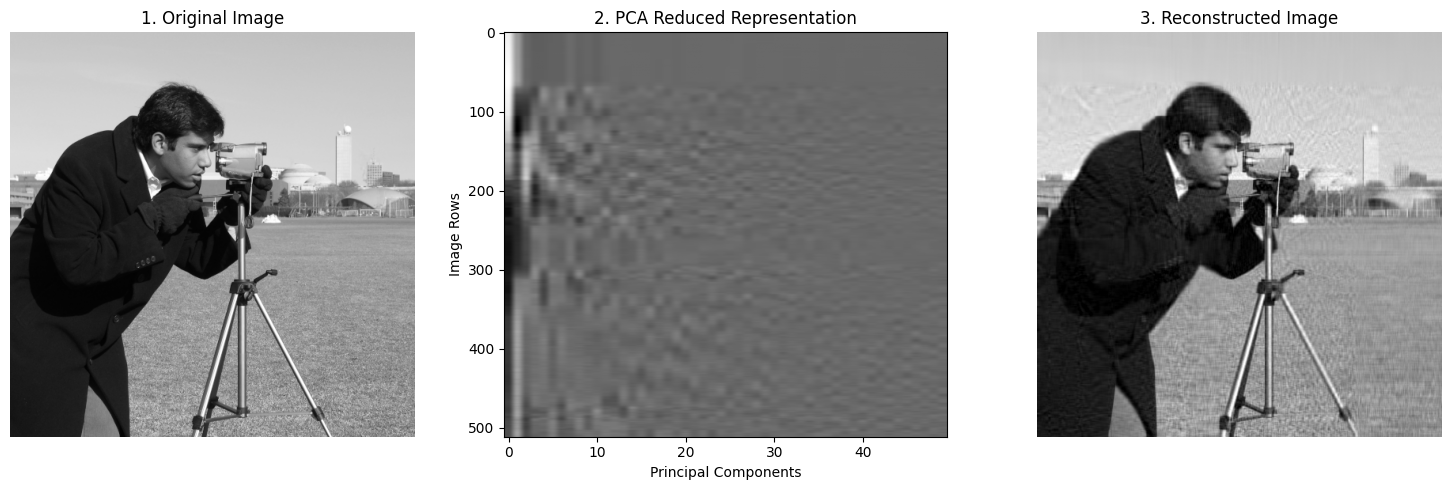

In [ ]:
# STEP 14: VISUALIZE PCA COMPRESSION PROCESS
# ============================================================

# Original image
# Reduced representation
# Reconstructed image

k = 50

pca = PCA(n_components=k)

reduced = pca.fit_transform(image)

reconstructed = pca.inverse_transform(reduced)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)

plt.imshow(image, cmap='gray')

plt.title("1. Original Image")

plt.axis('off')


plt.subplot(1,3,2)

plt.imshow(reduced, cmap='gray', aspect='auto')

plt.title("2. PCA Reduced Representation")

plt.xlabel("Principal Components")

plt.ylabel("Image Rows")


plt.subplot(1,3,3)

plt.imshow(reconstructed, cmap='gray', vmin=0, vmax=255)

plt.title("3. Reconstructed Image")

plt.axis('off')

plt.tight_layout()
plt.show()



========== FINAL PCA RESULTS ==========
Selected Components: 100
Variance Retained: 99.16 %
Reconstruction Error: 34.05
Original Image Size: (512, 512)
Reduced Image Size: (512, 100)


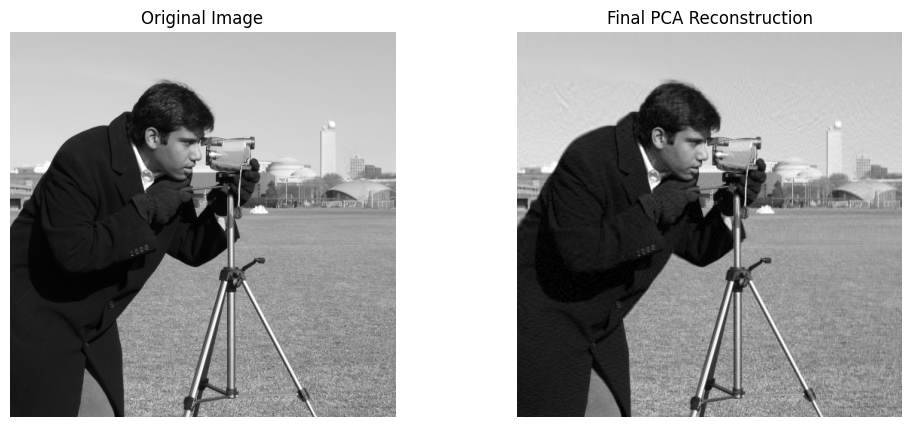


PCA IMAGE COMPRESSION COMPLETED!


In [ ]:
# STEP 15: FINAL EXPERIMENT
# ============================================================

# Students can change the number of components here

k = 100

pca = PCA(n_components=k)

reduced = pca.fit_transform(image)

reconstructed = pca.inverse_transform(reduced)

mse = np.mean((image - reconstructed)**2)

variance_retained = np.sum(pca.explained_variance_ratio_)

print("\n========== FINAL PCA RESULTS ==========")

print("Selected Components:", k)

print("Variance Retained:", round(variance_retained * 100, 2), "%")

print("Reconstruction Error:", round(mse, 2))

print("Original Image Size:", image.shape)

print("Reduced Image Size:", reduced.shape)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(reconstructed, cmap='gray', vmin=0, vmax=255)
plt.title("Final PCA Reconstruction")
plt.axis('off')
plt.show()
print("\nPCA IMAGE COMPRESSION COMPLETED!")